# ainvoke 요청 응답

**이 노트북에서 할 일**

1. 처리 함수 `chat`의 몸통이 에이전트 그래프를 await와 `ainvoke`로 부르는 줄을 읽습니다.
2. 비동기 노드만 있는 그래프를 동기 메서드 `invoke`로 부르면 오류가 나는 것을 봅니다.
3. await와 `ainvoke`로 같은 그래프를 불러, HTTP 응답과 같은 답을 받습니다.

**준비물** — 이 노트북은 모델을 부르지 않습니다.
모델 요청은 0번이고, API 키 없이 실행합니다.
예상 비용도 0달러입니다.
실습 앱의 에이전트 그래프는 모델을 쓰지 않고, 정해 둔 말로 답합니다.
그래서 다시 실행해도 같은 값이 나와야 합니다.

요청은 같은 노트북 안에서 앱 객체로 바로 들어갑니다.
서버 프로그램을 따로 띄우지 않고, 네트워크와 포트를 쓰지 않습니다.
실습 폴더의 파일을 가져오고 읽기만 하며, 쓰는 파일은 없습니다.

걸린 시간은 재지 않았습니다.
이 절은 앞 챕터에서 배운 함수를 쓰지 않아, 가져오는 도구 파일도 없습니다.

**기준 버전** — 첫 셀에서 패키지 여섯을 설치합니다.
판은 fastapi 0.135.0, httpx 0.28.1, pydantic 2.12.5, starlette 1.6.0입니다.
패키지 langgraph 1.2.11과 langchain 1.4.0은 실습 앱 파일이 가져오는 패키지입니다.
여섯 모두 실습 폴더 잠금과 같은 판입니다.

교재 출력은 Linux의 Python 3.12.13으로 만들었습니다.
다른 판과 Windows·macOS에서는 실행하지 않았습니다.

**강의와 실습 범위** — 강의 시간에는 2~5절을 읽습니다.
처리 함수가 그래프를 부르는 줄을 보고, 동기로 부르기와 비동기로 부르기를 Before·After로 봅니다.
6절은 노드 함수 하나를 바꿔 보는 실습이고, 실습 시간에 실행합니다.

실습 폴더 `labs/part7/ch30-fastapi-serving`에서 `uv sync --locked`를 실행합니다.
그다음 `notebooks/` 폴더의 이 노트북을 열고, 실습 폴더의 `.venv` 커널을 고릅니다.
첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

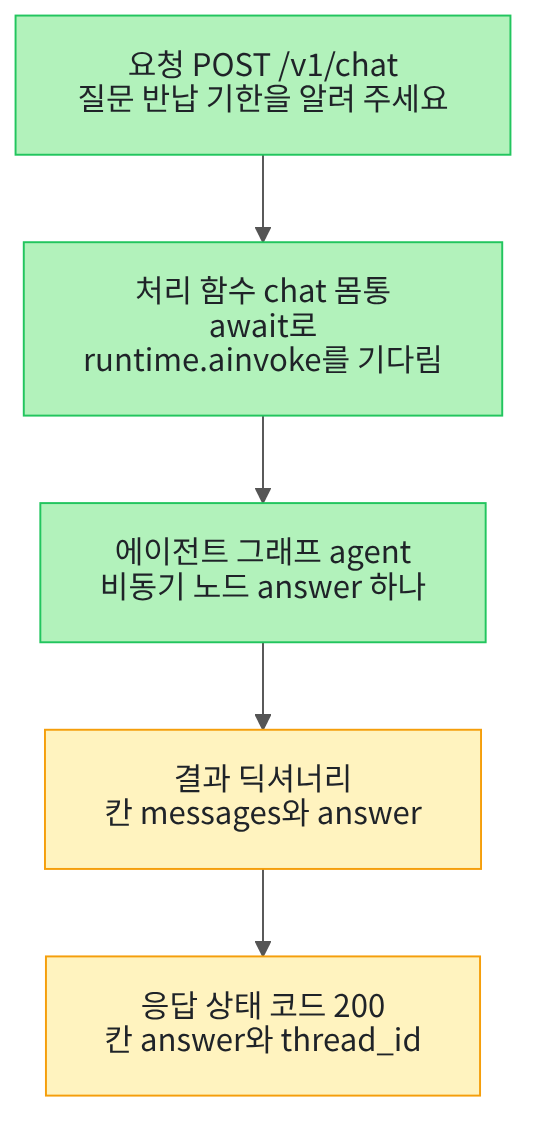

위에서 아래로 읽습니다.
초록 상자 셋은 보낸 요청과, 실습 폴더 파일의 처리 함수와 그래프입니다.
노란 상자 둘은 노트북 출력으로 확인한 결과의 칸과 응답입니다.
응답은 2절 출력에서, 결과의 칸은 5절 출력에서 봅니다.

## 1. 준비

02절에서는 처리 함수 `chat`이 의존성 셋의 값을 받는 것을 봤습니다.
이 절은 그 몸통이 에이전트 그래프를 부르는 줄을 봅니다.
제목의 ainvoke는 Ch 28 04절에서 본 비동기로 부르기입니다.
메서드 `invoke`의 비동기 판이고, 끝날 때까지 await로 기다리며 부릅니다.

첫 셀은 패키지 여섯을 설치하고 설치된 판 번호를 출력합니다.
설치에는 몇십 초가 걸릴 수 있습니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "fastapi==0.135.0" "httpx==0.28.1" "pydantic==2.12.5" "starlette==1.6.0" "langgraph==1.2.11" "langchain==1.4.0"
from importlib.metadata import version

print("fastapi:", version("fastapi"))
print("httpx:", version("httpx"))
print("pydantic:", version("pydantic"))
print("starlette:", version("starlette"))
print("langgraph:", version("langgraph"))
print("langchain:", version("langchain"))

Note: you may need to restart the kernel to use updated packages.
fastapi: 0.135.0
httpx: 0.28.1
pydantic: 2.12.5
starlette: 1.6.0


langgraph: 1.2.11
langchain: 1.4.0


**결과 읽기** — 출력 줄 `fastapi: 0.135.0`과 `langgraph: 1.2.11`이 보입니다.
여섯 모두 실습 폴더 잠금과 같은 판이고, 02절과 같은 목록입니다.
패키지 langgraph와 langchain은 실습 앱 파일이 가져옵니다.
이 절은 모델 객체를 만들지 않습니다.

다음 셀은 이 절에서 쓸 이름을 가져옵니다.
모듈 `inspect`는 함수 같은 객체의 정보를 꺼내 보는 모듈이고, 2절과 3절에서 씁니다.
이름 `StateGraph`·`START`·`END`는 Ch 13 01절에서 그래프를 만들 때 쓴 이름입니다.

In [2]:
# 이 절에서 쓸 이름을 가져옵니다(os·inspect는 Python에 들어 있는 모듈입니다)
import os
import inspect
from fastapi.testclient import TestClient
from langgraph.graph import END, START, StateGraph

print("가져온 이름:", "inspect, TestClient, StateGraph, START, END")

가져온 이름: inspect, TestClient, StateGraph, START, END


**결과 읽기** — 출력 줄 `가져온 이름: inspect, TestClient, StateGraph, START, END`가 보입니다.
이 노트북에는 API 키를 확인하는 셀이 없습니다.
모델을 부르지 않기 때문입니다.

다음 셀은 01절 2절과 같은 파일 위치 셀로, 후보 셋 가운데 실습 폴더를 고릅니다.

In [3]:
# 노트북을 연 자리에서 본 실습 폴더의 위치를 후보 셋 가운데에서 고릅니다
candidates = ["..", ".", "labs/part7/ch30-fastapi-serving"]
lab_path = None
for candidate in candidates:
    if os.path.exists(candidate + "/agent_service/schemas.py"):
        lab_path = candidate
        break
print("실습 폴더를 찾았는가:", lab_path is not None)
assert lab_path is not None, "notebooks 폴더나 실습 폴더 맨 위에서 노트북을 열어 주세요."

실습 폴더를 찾았는가: True


**결과 읽기** — 출력 줄 `실습 폴더를 찾았는가: True`가 보입니다.
고른 후보는 연 자리마다 달라서 출력하지 않습니다.

다음 셀은 02절처럼 작업 폴더를 실습 폴더로 옮긴 뒤 이름을 가져옵니다.
그래프 파일 `agent.py`에서는 상태 형식 `AgentState`, 에이전트 그래프 `agent`, 노드 함수 `answer_node`를 가져옵니다.
앱 파일 `app.py`에서는 앱 객체 `app`, 처리 함수 `chat`, 제공 함수 `get_agent`를 가져옵니다.
컴파일한 그래프의 속성 `nodes`는 노드 이름을 키로 둔 딕셔너리입니다.

In [4]:
# 작업 폴더를 실습 폴더로 옮기고, 그래프 파일과 앱 파일에서 이름을 가져옵니다
os.chdir(lab_path)
from agent_service.agent import AgentState, agent, answer_node
from agent_service.app import app, chat, get_agent
print("가져온 그래프의 종류:", type(agent).__name__)
print("그래프의 노드 이름:", list(agent.nodes))

가져온 그래프의 종류: CompiledStateGraph
그래프의 노드 이름: ['__start__', 'answer']


**결과 읽기** — 출력 줄 `가져온 그래프의 종류: CompiledStateGraph`가 보입니다.
노드 이름은 `['__start__', 'answer']`이고, 답을 만드는 노드는 `answer` 하나입니다.
이름 `__start__`는 Ch 13 01절에서 쓴 `START`의 값과 같은 이름입니다.
이 그래프는 모델을 쓰지 않고, 질문 앞에 정해 둔 말을 붙여 답합니다.

## 2. 처리 함수 몸통이 그래프를 부르는 줄

02절에서는 처리 함수 `chat`의 정의 줄까지 봤습니다.
다음 셀은 함수 `inspect.getsource`로 `chat`의 소스 글 전체를 출력합니다.
이 함수는 함수 객체를 받아, 그 함수를 적은 소스 글을 글자 그대로 내놓습니다.

In [5]:
# 앱 파일의 처리 함수 chat을 소스 글 그대로 출력합니다
# inspect.getsource는 함수 객체를 받아, 그 함수를 적은 소스 글을 내놓습니다
chat_source = inspect.getsource(chat)
print("처리 함수 chat의 소스:")
print(chat_source)

처리 함수 chat의 소스:
@app.post("/v1/chat", response_model=ChatResponse)
async def chat(body: ChatRequest, runtime: AgentDep, _token: AuthDep, timeout: TimeoutDep) -> ChatResponse:
    try:
        result = await asyncio.wait_for(
            runtime.ainvoke({"messages": [body.question]}), timeout=timeout
        )
    except TimeoutError as exc:
        raise HTTPException(status_code=504, detail="Agent 응답 시간이 초과되었습니다") from exc
    return ChatResponse(answer=result["answer"], thread_id=body.thread_id)



**결과 읽기** — 라벨 줄 아래에 데코레이터 줄부터 `return` 줄까지 아홉 줄이 있습니다.
몸통의 줄 `runtime.ainvoke({"messages": [body.question]})`가 그래프를 부르는 자리입니다.
그 앞의 줄 `await asyncio.wait_for(`는 02절에서 본 시간 제한입니다.
그래프가 끝나면 결과 딕셔너리가 이름 `result`에 담깁니다.
마지막 줄은 `result["answer"]`와 요청의 `thread_id`로 응답을 만듭니다.

처리 함수는 메서드 `ainvoke`로 부르고, 그 코루틴을 await로 기다립니다.
매개변수 `runtime`에는 02절의 제공 함수 `get_agent`가 내놓는 그래프가 들어옵니다.
다음 셀은 그 그래프가 방금 가져온 `agent`와 같은 객체인지 봅니다.
제공 함수를 셀 맨 위에서 await로 부르는 것은 02절과 같은 모양입니다.

In [6]:
# 처리 함수의 매개변수 runtime에 들어올 그래프가, 가져온 agent와 같은 객체인지 봅니다
runtime_graph = await get_agent()
print("runtime에 들어오는 그래프가 agent와 같은 객체인가:", runtime_graph is agent)

runtime에 들어오는 그래프가 agent와 같은 객체인가: True


**결과 읽기** — 출력 줄 `runtime에 들어오는 그래프가 agent와 같은 객체인가: True`가 보입니다.
처리 함수 몸통이 부르는 그래프는 이 노트북의 `agent`와 같은 객체입니다.
그래서 노트북에서 `agent`를 부르면, 처리 함수 몸통과 같은 그래프를 부르는 셈입니다.

다음 셀은 시험용 클라이언트로 실제로 요청을 넣어 봅니다.
요청 머리의 칸 `Authorization`에는 02절처럼 교재용 접근 토큰을 적습니다.

In [7]:
# 시험용 클라이언트로 POST /v1/chat 요청을 넣고, 상태 코드와 응답 본문을 봅니다
client = TestClient(app)
auth_headers = {"Authorization": "Bearer local-demo-token"}
question_body = {"question": "반납 기한을 알려 주세요", "thread_id": "ainvoke-01"}
http_response = client.post("/v1/chat", json=question_body, headers=auth_headers)
http_body = http_response.json()
print("상태 코드:", http_response.status_code)
print("응답 본문:", http_body)

상태 코드: 200
응답 본문: {'answer': '질문을 확인했습니다: 반납 기한을 알려 주세요', 'thread_id': 'ainvoke-01'}


**결과 읽기** — 출력 줄 `상태 코드: 200`이 보입니다.
응답 본문은 `{'answer': '질문을 확인했습니다: 반납 기한을 알려 주세요', 'thread_id': 'ainvoke-01'}`입니다.
처리 함수 몸통이 await로 그래프를 기다린 뒤, 결과의 답으로 응답을 만들었습니다.
응답 본문의 칸은 `answer`·`thread_id` 둘입니다.

## 3. 실습 그래프의 노드 함수

그래프가 어떻게 만들어졌는지 파일을 읽어 봅니다.
다음 셀은 그래프 파일을 글로 읽어, 세 가지 줄만 출력합니다.
상태 형식의 정의 줄, 노드 함수의 정의 줄, 노드를 더하는 줄입니다.

In [8]:
# 그래프 파일을 글로 읽어, 상태 형식·노드 함수의 정의 줄과 노드를 더하는 줄만 출력합니다
with open("agent_service/agent.py", encoding="utf-8") as agent_file:
    agent_text = agent_file.read()
print("상태 형식·노드 함수·노드를 더하는 줄:")
for line in agent_text.splitlines():
    if line.startswith("class ") or line.startswith("async def ") or "add_node(" in line:
        print(line)

상태 형식·노드 함수·노드를 더하는 줄:
class AgentState(TypedDict):
async def answer_node(state: AgentState) -> dict[str, object]:
    graph.add_node("answer", answer_node)


**결과 읽기** — 라벨 줄 아래 첫 줄은 `class AgentState(TypedDict):`입니다.
이 파일이 칸 `messages`·`answer`를 적어 둔 상태 형식입니다.
과정에는 같은 이름 `AgentState`가 셋 있습니다.
Ch 20 01절에서 우리가 적은 것, Ch 21 03절의 라이브러리 상태 형식, 그리고 이 실습 파일의 것입니다.
이 절의 `AgentState`는 셋째이고, 앞의 둘과 칸이 다릅니다.

둘째 줄은 노드 함수 `answer_node`의 정의 줄이고, `async def`로 시작합니다.
셋째 줄은 이 비동기 함수를 이름 `answer`의 노드로 더합니다.
다음 셀은 이 노드 함수가 비동기 함수인지 출력으로 확인합니다.

In [9]:
# 노드 함수 answer_node가 비동기 함수인지 봅니다
# inspect.iscoroutinefunction은 async def로 적은 함수면 True를 내놓습니다
print("answer_node가 비동기 함수인가:", inspect.iscoroutinefunction(answer_node))

answer_node가 비동기 함수인가: True


**결과 읽기** — 출력 줄 `answer_node가 비동기 함수인가: True`가 보입니다.
패키지 langgraph도 노드를 더할 때 같은 함수로 노드 함수를 살핍니다.
설치판 langgraph 1.2.11 `_internal/_runnable.py` 528~536행이 그 자리입니다.
비동기 함수이면 566~567행이 동기로 부를 함수 자리를 비워 둡니다.
이 동작은 설치판 소스로 보았고, 그 결과는 4절에서 출력으로 봅니다.

다음 셀은 처리 함수 몸통과 같은 모양의 입력을 만듭니다.

In [10]:
# 처리 함수 몸통과 같은 모양의 입력을 만듭니다(칸 messages에 질문 하나를 담은 목록)
question_input = {"messages": ["반납 기한을 알려 주세요"]}
print("입력:", question_input)

입력: {'messages': ['반납 기한을 알려 주세요']}


**결과 읽기** — 출력 줄 `입력: {'messages': ['반납 기한을 알려 주세요']}`가 보입니다.
처리 함수 몸통의 `{"messages": [body.question]}`와 같은 모양입니다.
질문도 2절에서 보낸 요청과 같습니다.

## 4. Ch 13·21처럼 invoke로 부르기 (Before)

그래프의 답만 빠르게 확인하고 싶을 때가 있습니다.
Ch 13 01절과 Ch 21 01절에서는 그래프를 메서드 `invoke`로 불렀습니다.
Before에서는 실습 그래프를 그 방법 그대로 부릅니다.
오류가 나면 저장된 출력에 긴 오류 기록이 남으므로, Ch 2 05절의 `try`와 `except`로 받아 출력합니다.
Ch 28 04절에서 MCP 도구를 `invoke`로 불러 본 셀과 같은 모양입니다.

실행 전에 예상해 봅니다.
동기 메서드로 비동기 노드를 부르면 답을 받을 수 있을까요?

In [11]:
# Before: 비동기 노드만 있는 그래프를 동기 메서드 invoke로 부릅니다(오류 TypeError만 받습니다)
error_lines = []
try:
    agent.invoke(question_input)
except TypeError as error:
    print("받은 오류:", type(error).__name__)
    # 오류 글이 여러 줄이라, 줄마다 나눈 목록으로 담아 둡니다
    error_lines = str(error).splitlines()
print("오류 글의 줄 수:", len(error_lines))

받은 오류: TypeError
오류 글의 줄 수: 2


**결과 읽기** — 출력 줄 `받은 오류: TypeError`와 `오류 글의 줄 수: 2`가 보입니다.
그래프는 답을 내지 못하고, 오류 `TypeError`로 끝났습니다.
오류 글은 두 줄이라, 다음 셀에서 한 줄씩 출력합니다.

In [12]:
# 받은 오류 글을 한 줄씩 출력합니다
print("받은 오류 글:")
for line in error_lines:
    print(line)

받은 오류 글:
No synchronous function provided to "answer".
Either initialize with a synchronous function or invoke via the async API (ainvoke, astream, etc.)


**결과 읽기** — 라벨 줄 아래 첫 줄은 `No synchronous function provided to "answer".`입니다.
노드 `answer`에 동기로 부를 함수가 없다는 뜻입니다.
둘째 줄은 동기 함수로 노드를 만들거나, 비동기로 부르라고 적습니다.
괄호 안의 `ainvoke`와 `astream`이 비동기로 부르는 메서드입니다.
이것이 이 절의 Before 결함입니다.

설치판 `_internal/_runnable.py` 377~382행이 이 오류를 내는 자리입니다.
3절에서 본 대로 노드 함수가 비동기 함수라, 동기로 부를 함수 자리가 비어 있었습니다.
다음 셀은 Ch 25 01절에서 배운 동기 메서드 `stream`으로도 불러 봅니다.

In [13]:
# Ch 25 01절의 동기 메서드 stream으로도 불러 봅니다(오류 TypeError만 받습니다)
try:
    for event in agent.stream(question_input):
        print("받은 스트림 사건:", event)
except TypeError as error:
    stream_lines = str(error).splitlines()
    print("받은 오류:", type(error).__name__)
    print("오류 글이 invoke 때와 같은가:", stream_lines == error_lines)

받은 오류: TypeError
오류 글이 invoke 때와 같은가: True


**결과 읽기** — 출력 줄 `받은 오류: TypeError`와 `오류 글이 invoke 때와 같은가: True`가 보입니다.
라벨 `받은 스트림 사건:`이 붙은 줄은 하나도 없습니다.
스트림 사건을 하나도 받지 못하고 같은 오류로 끝났습니다.
설치판 `pregel/main.py`를 보면 메서드 `invoke`도 안에서 `stream`을 부릅니다.
그래서 두 동기 메서드가 같은 자리에서 같은 오류를 냈습니다.

## 5. await와 ainvoke로 부르기 (After)

After에서는 처리 함수 몸통과 같은 방법으로 부릅니다.
메서드 `ainvoke`는 Ch 28 04절에서 본 `invoke`의 비동기 판입니다.
Ch 2 12절에서는 비동기 함수를 부르기만 하면 코루틴이 나온다고 배웠습니다.
코루틴은 아직 실행하지 않은 본문 실행 하나이고, await 줄에서 본문이 실행됩니다.
다음 셀은 먼저 `ainvoke`를 await 없이 부르기만 합니다.

In [14]:
# After 첫 단계: ainvoke를 await 없이 부르기만 하고, 받은 값의 종류를 봅니다
pending = agent.ainvoke(question_input)
print("부르기만 해서 받은 값의 종류:", type(pending).__name__)

부르기만 해서 받은 값의 종류: coroutine


**결과 읽기** — 출력 줄 `부르기만 해서 받은 값의 종류: coroutine`이 보입니다.
그래프는 아직 실행되지 않았고, 이름 `pending`에 코루틴 하나가 담겼습니다.
Ch 2 12절에서 비동기 함수를 부르기만 했을 때와 같은 결과입니다.

다음 셀은 이 코루틴 앞에 await를 붙여, 그래프가 끝날 때까지 기다립니다.
셀 맨 위의 await 줄은 02절처럼 노트북 도구(IPython)의 기능입니다.

In [15]:
# 코루틴 앞에 await를 붙여, 그래프가 끝날 때까지 기다린 뒤 결과를 받습니다
result = await pending
print("await로 받은 값의 종류:", type(result).__name__)
print("결과의 칸:", list(result))
print("칸 answer:", result["answer"])
print("칸 messages:", result["messages"])

await로 받은 값의 종류: dict
결과의 칸: ['messages', 'answer']
칸 answer: 질문을 확인했습니다: 반납 기한을 알려 주세요
칸 messages: ['반납 기한을 알려 주세요']


**결과 읽기** — 출력 줄 `await로 받은 값의 종류: dict`와 `결과의 칸: ['messages', 'answer']`가 보입니다.
칸 `answer`는 `질문을 확인했습니다: 반납 기한을 알려 주세요`입니다.
칸 `messages`는 입력으로 넣은 질문 목록 그대로입니다.
await 줄에서 그래프가 끝까지 실행되었고, 끝난 뒤의 상태를 한 번에 받았습니다.

다음 셀은 2절에서 받은 HTTP 응답 본문과 이 결과를 견줍니다.

In [16]:
# 2절에서 처리 함수가 HTTP로 내준 응답과, 노트북에서 부른 그래프의 결과를 견줍니다
print("응답 본문의 칸:", list(http_body))
print("결과의 칸:", list(result))
print("두 답이 같은가:", http_body["answer"] == result["answer"])

응답 본문의 칸: ['answer', 'thread_id']
결과의 칸: ['messages', 'answer']
두 답이 같은가: True


**결과 읽기** — 출력 줄 `응답 본문의 칸: ['answer', 'thread_id']`와 `두 답이 같은가: True`가 보입니다.
결과의 칸은 `['messages', 'answer']`이고, 응답 본문에는 칸 `messages`가 없습니다.
처리 함수는 결과에서 칸 `answer`만 골라, 요청의 `thread_id`와 함께 응답을 만들었습니다.
응답 본문의 칸 둘은 01절에서 본 응답 형식 `ChatResponse`의 칸입니다.

노트북과 처리 함수는 같은 그래프를 같은 방법, 곧 await와 `ainvoke`로 불렀습니다.
그래서 두 답이 같았습니다.

## 6. 값 바꿔 보기: 노드 함수를 def로

값 하나만 바꿔 봅니다.
바꿀 것은 노드 함수의 정의 줄로, `async def` 대신 `def`로 적습니다.
상태 형식은 실습 파일의 `AgentState`로, 노드 이름과 답을 만드는 규칙도 같게 둡니다.
다음 셀은 그 동기 노드 함수를 정의합니다.

In [17]:
# 값 바꿔 보기: 실습 노드와 같은 답을 만드는 동기 노드 함수를 def로 정의합니다
def sync_answer_node(state):
    # 목록 messages의 마지막 질문 앞에, 실습 노드와 같은 말을 붙입니다
    question = state["messages"][-1]
    return {"answer": "질문을 확인했습니다: " + question}

**결과 읽기** — 정의 셀이라 출력이 없습니다.
실습 노드처럼 목록 `messages`의 마지막 질문 앞에 정해 둔 말을 붙입니다.
실습 노드에는 답을 낱말마다 나눠 적는 줄도 있지만, 이 함수는 답만 내놓습니다.
그 줄은 04절에서 봅니다.

다음 셀은 Ch 13 01절처럼 이 함수로 노드 하나인 그래프를 만들고 컴파일합니다.

In [18]:
# 실습 파일의 상태 형식 AgentState로, 노드 하나인 그래프를 Ch 13 01절처럼 만듭니다
sync_builder = StateGraph(AgentState)
sync_builder.add_node("answer", sync_answer_node)
sync_builder.add_edge(START, "answer")
sync_builder.add_edge("answer", END)
sync_graph = sync_builder.compile()
print("노드 함수가 비동기 함수인가:", inspect.iscoroutinefunction(sync_answer_node))
print("그래프의 노드 이름:", list(sync_graph.nodes))

노드 함수가 비동기 함수인가: False
그래프의 노드 이름: ['__start__', 'answer']


**결과 읽기** — 출력 줄 `노드 함수가 비동기 함수인가: False`가 보입니다.
노드 이름은 실습 그래프와 같은 `['__start__', 'answer']`입니다.
달라진 것은 노드 함수의 정의 줄 하나입니다.

다음 셀은 이 그래프를 4절에서 오류가 난 동기 메서드 `invoke`로 부릅니다.
실행 전에 예상해 봅니다.
이번에도 오류가 날까요?

In [19]:
# 동기 노드 그래프를, 4절에서 오류가 난 동기 메서드 invoke로 부릅니다
sync_result = sync_graph.invoke(question_input)
print("결과의 칸:", list(sync_result))
print("칸 answer:", sync_result["answer"])

결과의 칸: ['messages', 'answer']
칸 answer: 질문을 확인했습니다: 반납 기한을 알려 주세요


**결과 읽기** — 출력 줄 `결과의 칸: ['messages', 'answer']`가 보입니다.
칸 `answer`는 `질문을 확인했습니다: 반납 기한을 알려 주세요`입니다.
노드 함수를 `def`로 적자, 동기 메서드 `invoke`가 오류 없이 답을 받았습니다.

다음 셀은 같은 그래프를 await와 `ainvoke`로도 부릅니다.
동기 노드 그래프도 비동기로 부를 수 있을까요?

In [20]:
# 같은 동기 노드 그래프를 await와 ainvoke로도 부르고, 답을 견줍니다
async_result = await sync_graph.ainvoke(question_input)
print("ainvoke로 받은 칸 answer:", async_result["answer"])
print("invoke 답과 같은가:", async_result["answer"] == sync_result["answer"])
print("실습 그래프의 답과 같은가:", async_result["answer"] == result["answer"])

ainvoke로 받은 칸 answer: 질문을 확인했습니다: 반납 기한을 알려 주세요
invoke 답과 같은가: True
실습 그래프의 답과 같은가: True


**결과 읽기** — 출력 줄 `invoke 답과 같은가: True`와 `실습 그래프의 답과 같은가: True`가 보입니다.
동기 노드 그래프는 `invoke`와 `ainvoke` 모두로 부를 수 있었습니다.
비동기 노드만 있는 실습 그래프는 `ainvoke`로만 부를 수 있었습니다.

설치판 `_internal/_runnable.py` 569~574행은 동기 노드 함수에 비동기 판을 함께 만들어 둡니다.
그 비동기 판은 동기 함수를 다른 스레드에서 부르며, 노트북에서는 스레드를 확인하지 않았습니다.
다음 셀은 이 그래프를 02절의 재정의로 처리 함수에 넘기려고, 제공 함수 하나를 정의합니다.

In [21]:
# 재정의에 쓸, 동기 노드 그래프를 내놓는 제공 함수를 정의합니다
async def get_sync_graph():
    return sync_graph

**결과 읽기** — 정의 셀이라 출력이 없습니다.
02절의 `zero_timeout`처럼 이름 있는 비동기 함수이고, 늘 `sync_graph`를 내놓습니다.

다음 셀은 재정의 딕셔너리에 `get_agent` 대신 이 함수를 적고, 2절과 같은 요청을 넣습니다.
02절 Before처럼 재정의가 남지 않도록, 요청을 넣은 바로 뒤에 딕셔너리를 비웁니다.

In [22]:
# get_agent 대신 get_sync_graph를 재정의로 적고, 2절과 같은 요청을 넣은 뒤 바로 비웁니다
app.dependency_overrides[get_agent] = get_sync_graph
sync_response = client.post("/v1/chat", json=question_body, headers=auth_headers)
app.dependency_overrides.clear()
print("상태 코드:", sync_response.status_code)
print("응답 본문:", sync_response.json())
print("2절 응답 본문과 같은가:", sync_response.json() == http_body)
print("재정의 딕셔너리의 키 수:", len(app.dependency_overrides))

상태 코드: 200
응답 본문: {'answer': '질문을 확인했습니다: 반납 기한을 알려 주세요', 'thread_id': 'ainvoke-01'}
2절 응답 본문과 같은가: True
재정의 딕셔너리의 키 수: 0


**결과 읽기** — 출력 줄 `상태 코드: 200`과 `2절 응답 본문과 같은가: True`가 보입니다.
재정의 딕셔너리의 키 수는 `0`이라, 재정의는 남지 않았습니다.
처리 함수 몸통은 넘겨받은 그래프를 늘 await와 `ainvoke`로 부릅니다.
그래서 노드 함수가 `def`인 그래프를 넘겨도 같은 답을 냈습니다.

## 정리

1. 처리 함수 `chat`의 몸통은 에이전트 그래프를 await와 `ainvoke`로 불러, 끝난 결과를 한 번에 받았습니다.
2. 비동기 노드만 있는 그래프를 동기 메서드 `invoke`·`stream`으로 부르자 오류 `TypeError`가 났습니다.
3. 노드 함수를 `def`로 바꾼 그래프는 두 메서드로 모두 답했고, 처리 함수에 넘겨도 답했습니다.

04절에서는 비동기 메서드 `astream`으로 모드 `custom`의 스트림 사건을 받아 이어 붙입니다.